# Solution for the second science case

In [ ]:
# needed Python imports
# imports for data retrieve
import splusdata
import numpy as np
from PIL import Image
from matplotlib import pyplot as plt

# auxiliar functions and variables

# https://github.com/splus-collab/splus_filters for S-PLUS filters information
splus_bands = [
    'u', 'J0378', 'J0395', 'J0410', 'J0430', 
    'g', 'J0515', 'r', 'J0660', 'i', 'J0861', 'z',
]
# pivot wavelenght of S-PLUS filters 
splut_bands_pivot_wavelenghts = [
    3533.28, 3773.16, 3940.7, 4094.93, 
    4292.11, 4758.49, 5133.13, 6251.83, 
    6613.88, 7670.61, 8607.25, 8941.48
]

In [3]:
conn = splusdata.Core()

## S-PLUS Catalogs choice

In [4]:
query = """
select
top 10000
    i.id,
    i.field,
    i.ra,
    i.dec,

    i.a_pixel_det,
    i.isophotal_area_pixel_det,

    i.mag_auto_*,
    i.s2n_auto_*,
    sqg.prob_gal
    
from idr6.idr6 as i
join idr6.vac_sqg as sqg on i.id = sqg.id

where
    s2n_auto_g > 5
    and s2n_auto_r > 5
    and s2n_auto_i > 5
    and s2n_auto_j0660 > 5

    and s2n_auto_g != 99
    and s2n_auto_r != 99
    and s2n_auto_i != 99
    and s2n_auto_j0660 != 99

    and mag_auto_g > 14
    and mag_auto_r > 14
    and mag_auto_i > 14
    and mag_auto_j0660 > 14

    and mag_auto_g < 22
    and mag_auto_r < 22
    and mag_auto_i < 22
    and mag_auto_j0660 < 22
    
    and prob_gal > 0.98
    and cone(i.ra, i.dec, 54.5, -35.5, 0.5)
"""

tab = conn.query(query)

In [5]:
cone_center_coord = 54.5, -35.5 

In [6]:
tab

,id,field,ra,dec,a_pixel_det,isophotal_area_pixel_det,mag_auto_g,mag_auto_i,mag_auto_j0378,mag_auto_j0395,...,s2n_auto_j0395,s2n_auto_j0410,s2n_auto_j0430,s2n_auto_j0515,s2n_auto_j0660,s2n_auto_j0861,s2n_auto_r,s2n_auto_u,s2n_auto_z,prob_gal
0,i06s28s3300UIP,SPLUS-s28s33,54.097836,-35.869127,2.093676,35,19.667422,19.553542,20.199837,20.331481,...,2.104068,3.859133,4.701851,5.893542,9.442190,3.765777,14.803575,6.053682,4.971102,0.994
1,i06s28s3400PUA,SPLUS-s28s34,54.114072,-35.878494,3.673194,53,20.281349,19.391057,20.741699,20.754351,...,2.605742,1.687804,3.966312,6.240044,18.989870,9.561979,20.462778,6.185396,12.876625,0.997
2,i06s28s3300UD2,SPLUS-s28s33,54.114123,-35.878431,3.942653,63,19.498619,18.751554,20.698207,19.671881,...,2.593244,0.940831,1.205255,4.295157,11.135935,7.522405,15.412335,2.455774,8.179150,0.998
3,i06s28s3300VQP,SPLUS-s28s33,54.084972,-35.831693,1.500981,19,20.663286,19.833010,22.103320,21.104571,...,1.861581,2.243413,1.269089,4.479990,8.738814,5.967836,10.084186,3.564836,4.749761,0.996
4,i06s28s3300TBF,SPLUS-s28s33,54.161676,-35.908139,2.021320,40,20.377502,18.851710,20.234184,NaN,...,-0.325746,0.711256,2.135614,3.660693,16.183598,10.447568,20.945425,2.689553,14.381163,0.999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
788,i06s27s3400F28,SPLUS-s27s34,54.895693,-35.122869,2.231787,49,19.893898,18.354868,20.355401,NaN,...,-0.091033,1.472659,4.519432,6.456612,28.918228,15.204344,24.678290,0.805735,20.561571,0.997
789,i06s27s35009FX,SPLUS-s27s35,55.039318,-35.265066,2.506407,71,19.960197,18.273969,20.836482,20.769727,...,1.712003,0.492020,2.787664,8.733604,29.791822,15.876029,33.145120,2.509226,25.135740,0.999
790,i06s27s3400AIZ,SPLUS-s27s34,55.039500,-35.265003,2.271831,56,19.973325,18.211872,21.170537,NaN,...,-0.355950,2.454856,3.749049,6.425172,25.008188,17.093014,25.193857,2.602707,24.907595,0.999
791,i06s27s3400I7Z,SPLUS-s27s34,54.637576,-35.019247,2.211924,34,20.713953,19.433163,21.211957,21.123714,...,2.798446,2.677673,3.665409,4.315081,14.709315,9.493429,16.210045,2.699642,11.840036,0.997


## Search for objects using the crossmatch result table

###  Spatial distribution plot

Text(0.5, 0, 'DEC')

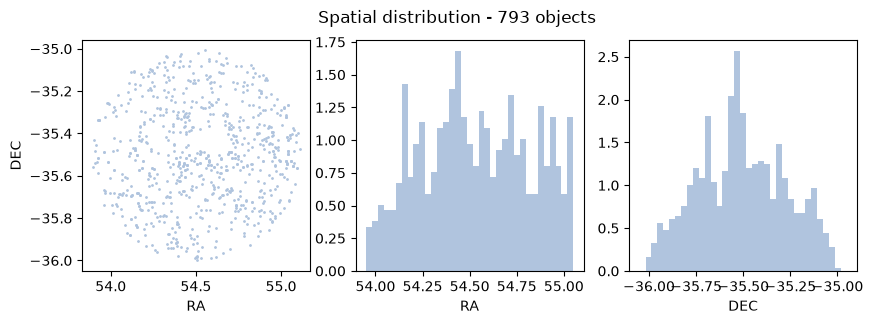

In [7]:
f, (ax1, ax2, ax3) = plt.subplots(1, 3)
f.set_size_inches(10, 3)
N = len(tab)
f.suptitle(f'Spatial distribution - {N} objects')
ra = tab['ra']
dec = tab['dec']
x = 0.5
ra_range = cone_center_coord[0]+np.array([-1.1*x, 1.1*x])
dec_range = cone_center_coord[1]+np.array([-1.1*x, 1.1*x])
ax1.scatter(ra, dec, s=1, c='lightsteelblue')
ax1.set_xlabel('RA')
ax1.set_ylabel('DEC')
ax2.hist(ra, bins=35, range=ra_range, density=True, color='lightsteelblue', histtype='stepfilled')
ax2.set_xlabel('RA')
ax3.hist(dec, bins=35, range=dec_range, density=True, color='lightsteelblue', histtype='stepfilled')
ax3.set_xlabel('DEC')

### Galaxies CMD plot (coloured by J0660 mag)

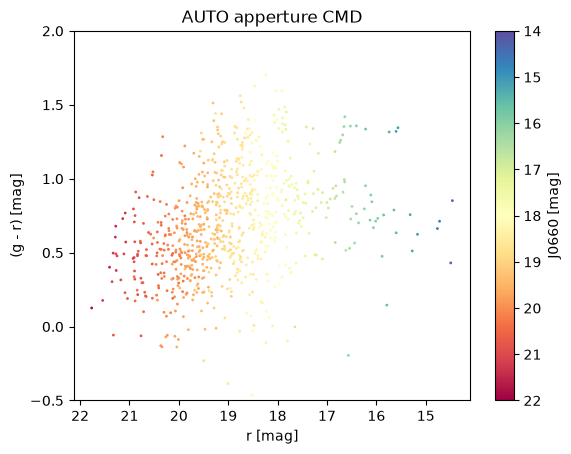

In [8]:
x = tab[f'mag_auto_r']
y = tab[f'mag_auto_g'] - tab[f'mag_auto_r']
z = tab[f'mag_auto_j0660']

f, ax = plt.subplots()
im = ax.scatter(x, y, c=z, s=1, cmap='Spectral_r', vmin=14, vmax=22)
ax.set_title(f'AUTO apperture CMD')
cax = plt.colorbar(im, ax=ax)
cax.ax.set_ylabel('J0660 [mag]')
cax.ax.invert_yaxis()
ax.set_xlabel(f'r [mag]')
ax.set_ylabel(f'(g - r) [mag]')
ax.set_ylim(-0.5, 2)
ax.invert_xaxis()

### Find a big galaxy among the sources above

We can use photometry to search for a big galaxy among all the sources found in the crossmatch. In special we will search for the biggest *ISOarea* values and use the *A* parameter to *estimate* a size to plot a thumbnail of the source using [splusdata](https://github.com/Schwarzam/splusdata). This procedure will help us to create an IFS-like cube using [S-Cubes](https://github.com/elacerda/s-cubes).

0 SPLUS-s27s34 54.80560887985572 -35.37144052350744 3553092.785454545
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3B82DDB50>


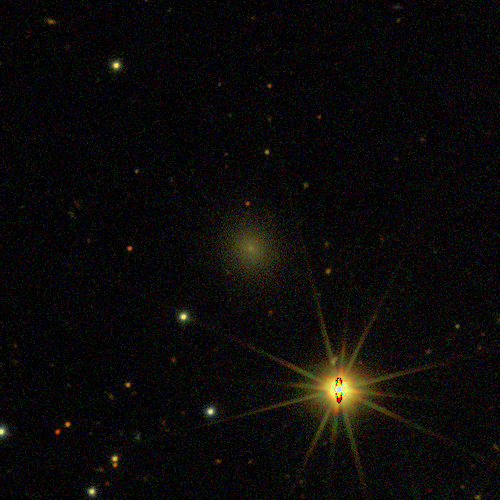

1 SPLUS-s28s34 55.036458900831235 -35.61449454785418 12719057.890909089
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3B823BB10>


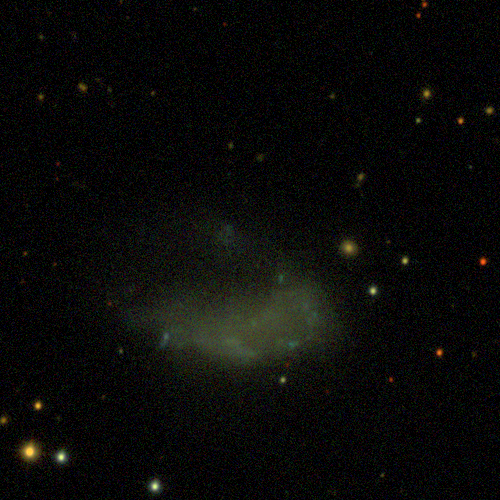

2 SPLUS-s27s34 54.23660902827557 -35.48209591842061 11780836.952727271
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3B824D8D0>


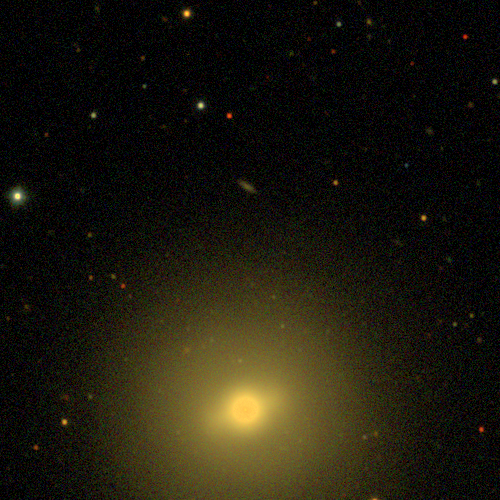

3 SPLUS-s27s34 54.580196413886654 -35.12915691383579 2563244.3127272725
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3B824D850>


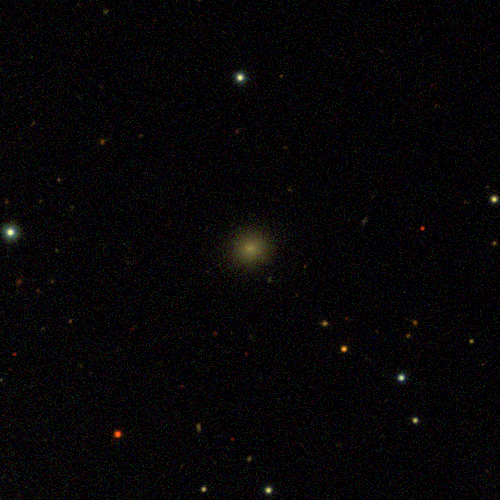

4 SPLUS-s28s34 54.26892345550354 -35.59004005094284 2717642.88
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3B821C490>


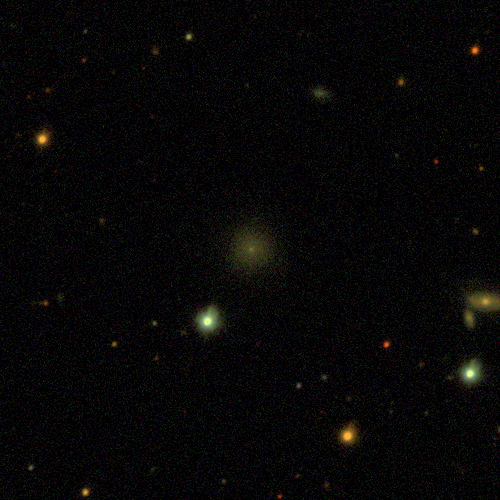

5 SPLUS-s27s34 54.94929874821829 -35.395570352905125 2090966.0072727273
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3B83651D0>


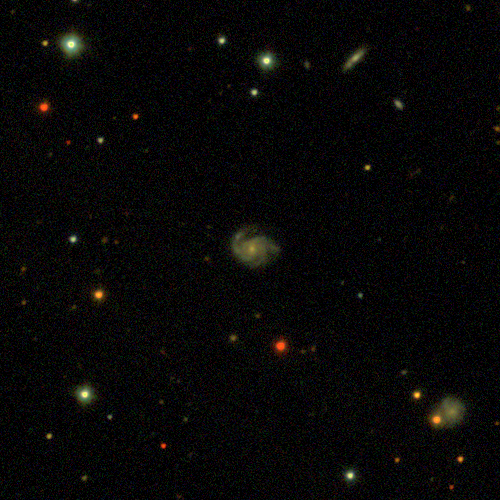

6 SPLUS-s28s34 54.83192762412151 -35.72450300989686 2632636.0799999996
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3B81BD9D0>


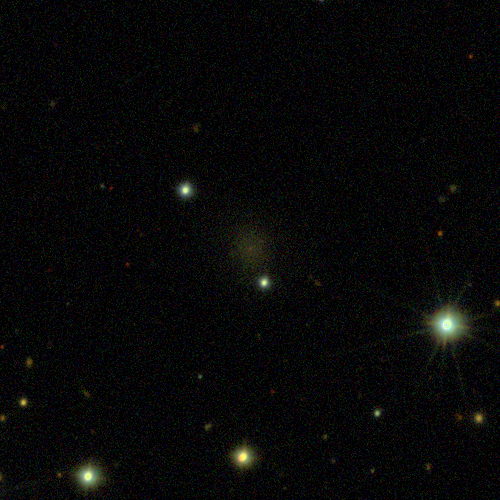

7 SPLUS-s28s34 54.46385689190031 -35.79320498263315 2094116.269090909
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3B833A890>


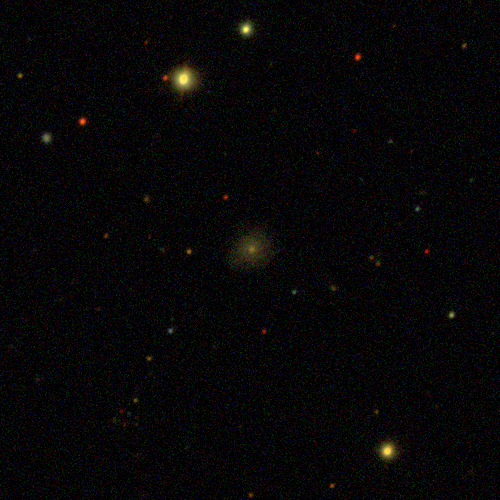

8 SPLUS-s27s34 54.58960616833112 -35.259720779156254 1930973.4327272724
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3BABB3E50>


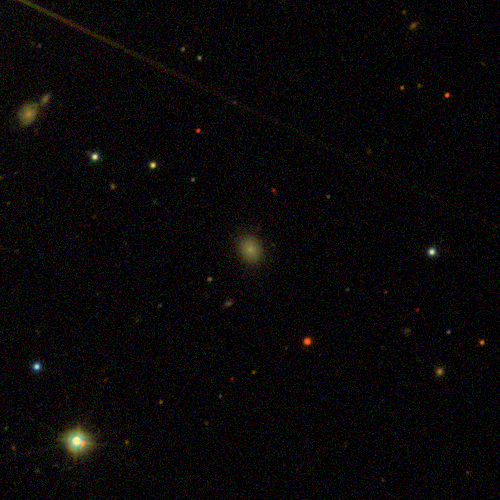

9 SPLUS-s28s34 54.224817808855576 -35.59779581743591 2173510.996363636
<PIL.PngImagePlugin.PngImageFile image mode=RGB size=500x500 at 0x7DB3B82797D0>


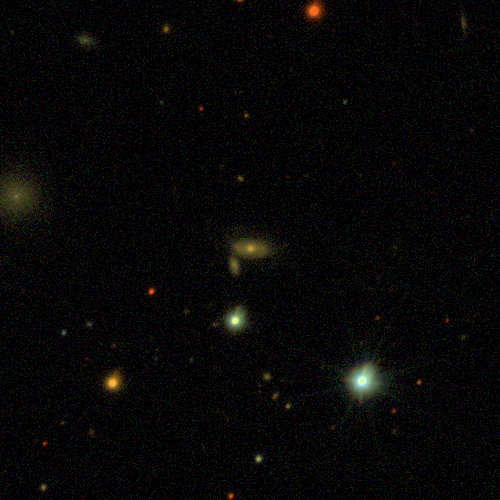

In [9]:
N_sources_to_print = 10
# Sort objects_table by ISOarea value and extract a table with the 
# N_sources_to_print first sources. Feel free to inspect as much 
# sources you want.
df = tab.sort_values(by='isophotal_area_pixel_det', ascending=False).head(N_sources_to_print)
sources_thumbs = []
for i, row in enumerate(df.itertuples()):
    ra = row.ra
    dec = row.dec

    # guess source size to create a inspect thumbnail
    A_arcsec = row.a_pixel_det*3600
    A_pix = A_arcsec/0.55 
    guess_size_pix = 30*A_pix

    print(i, row.field, ra, dec, guess_size_pix)

    # try to display the thumbnail
    try:
        img = conn.lupton_rgb(ra, dec, 500, 'I', 'R', 'G', data_release='idr6', field_name = row.field)
        print(img)
        img = img.transpose(Image.FLIP_TOP_BOTTOM)
        display(img)
        sources_thumbs.append(img)
    except Exception as e:
        print(f"Error displaying image for row {i}: {e}")
        pass